In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict

### Load env variables

In [2]:
load_dotenv()

True

### Define LLM

In [3]:
model  = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash"
)

### Define State

In [4]:
class TravelState(TypedDict):

    destination: str
    number_of_days: int

    sightseeing_plan: str
    food_recommendations: str
    transport_options: str

    final_plan: str

### Creating Nodes
First Node: Sight Seeing

In [5]:
def plan_sightseeing(state: TravelState):

    prompt = f"""
    Create a sightseeing plan for {state['destination']}
    for {state['number_of_days']} days.

    Suggest important places to visit and briefly explain
    why each place is worth visiting.
    """

    output = model.invoke(prompt)

    return {
        'sightseeing_plan': output.content
    }

Second Node: Food Recommendations

In [6]:
def recommend_food(state: TravelState):

    prompt = f"""
    Recommend food and dining options for a person visiting
    {state['destination']}.

    Include local dishes, popular types of restaurants,
    and foods the visitor should try.
    """

    output = model.invoke(prompt)

    return {
        'food_recommendations': output.content
    }

Third Node: Transportations

In [7]:
def suggest_transport(state: TravelState):

    prompt = f"""
    Explain the best transportation options for a tourist
    visiting {state['destination']} for {state['number_of_days']} days.

    Discuss public transportation, taxis, walking, and
    other useful options.
    """

    output = model.invoke(prompt)

    return {
        'transport_options': output.content
    }

Final Node: Create Travel Plan

In [8]:
def create_final_plan(state: TravelState):

    prompt = f"""
    Create a complete travel plan using the following information.

    Destination:
    {state['destination']}

    Number of Days:
    {state['number_of_days']}

    Sightseeing Plan:
    {state['sightseeing_plan']}

    Food Recommendations:
    {state['food_recommendations']}

    Transportation Options:
    {state['transport_options']}

    Organize the information into a practical travel plan.
    """

    output = model.invoke(prompt)

    return {
        'final_plan': output.content
    }

### Define and Compile Graph

In [13]:
# Define Graph
graph = StateGraph(TravelState)

# Add Nodes
graph.add_node('plan_sightseeing', plan_sightseeing)
graph.add_node('recommend_food', recommend_food)
graph.add_node('suggest_transport', suggest_transport)
graph.add_node('create_final_plan', create_final_plan)

# Add parallel edges
graph.add_edge(START, 'plan_sightseeing')
graph.add_edge(START, 'recommend_food')
graph.add_edge(START, 'suggest_transport')

# Connect parallel nodes to final node
graph.add_edge('plan_sightseeing', 'create_final_plan')
graph.add_edge('recommend_food', 'create_final_plan')
graph.add_edge('suggest_transport', 'create_final_plan')

# Final node to END
graph.add_edge('create_final_plan', END)

# Compile graph
workflow = graph.compile()

### Execute Graph

In [14]:
# intitial input
initial_state = {
    'destination': 'Istanbul',
    'number_of_days': 3
}

# execute graph
result = workflow.invoke(initial_state)

print("SIGHTSEEING:")
print(result['sightseeing_plan'])

print("\nFOOD:")
print(result['food_recommendations'])

print("\nTRANSPORT:")
print(result['transport_options'])

print("\nFINAL PLAN:")
print(result['final_plan'])

ChatGoogleGenerativeAIError: Error calling model 'gemini-3.6-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.6-flash\nPlease retry in 46.475128726s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-Fre

### Visualize graph

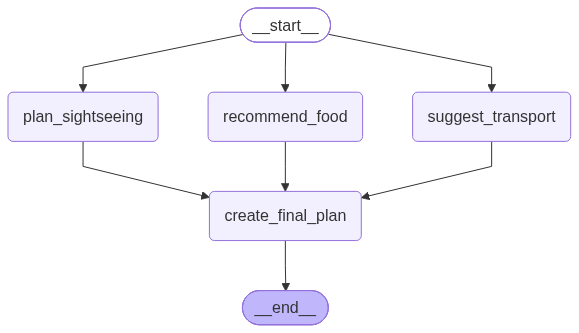

In [15]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())